# 1. Project Overview — Fake Job Posting Fraud Detection
Classify job postings as **Genuine (0)** vs **Fraudulent (1)** with a multimodal network:
parallel **BERT + TF-IDF + BoW** text branches and a **CNN** image branch, fused 896 -> 512 -> 256 -> 2.
Run cells top to bottom. Central settings live in Section 3; nothing below hard-codes key hyperparameters.

In [1]:
# 2. Imports
import os, time, random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE, ADASYN
print('imports OK')

imports OK


In [5]:
# 3. Configuration (single source of truth — edit here, nowhere else)
SEED = 42
BATCH_SIZE = 8            # safe for 6 GB VRAM alongside frozen BERT
NUM_EPOCHS = 10
MAX_LEN = 256             # BERT truncation length
TFIDF_FEATURES = 1000
BOW_FEATURES = 500
DROPOUT_RATE = 0.4
FREEZE_BERT = True        # keep True on RTX 3050 6GB; False = full fine-tune (needs much more VRAM)
USE_CLASS_WEIGHTS = True  # weighted CE loss computed on TRAIN only
USE_SMOTE = False         # not used in DL pipeline (see 11b); kept for classical baselines
USE_ADASYN = False
USE_AUXILIARY_LOSSES = True   # set False for ablation #8
EARLY_STOPPING_PATIENCE = 3
MONITOR_METRIC = 'fraud_f1'   # never accuracy alone
THRESHOLD = 0.50              # operating default; tuned on VALIDATION in Section 25
MAX_GRAD_NORM = 1.0
PRECOMPUTE_BERT = False   # optional one-time embedding cache (Section 12b); default off
ACTIVE_BRANCHES = {'tfidf': True, 'bow': True, 'bert': True, 'img': True}  # ablation control (26)
DATA_PATH = r'C:\DEV\FAKE ML\Dataset\fake_job_postings.csv'
IMAGE_BASE_PATH = r'C:\DEV\FAKE ML\Dataset\images'
BEST_CKPT = 'best_multimodal_model.pth'
FINAL_CKPT = 'multimodal_model_final.pth'
print('config loaded: SEED=%d BATCH=%d EPOCHS=%d FREEZE_BERT=%s' % (SEED, BATCH_SIZE, NUM_EPOCHS, FREEZE_BERT))

config loaded: SEED=42 BATCH=8 EPOCHS=10 FREEZE_BERT=True


In [6]:
# 4. Reproducibility — seed everything once
import torch
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_all()
g = torch.Generator().manual_seed(SEED)  # deterministic DataLoader shuffling
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
autocast_device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('seed=%d device=%s' % (SEED, device))

seed=42 device=cuda


## 5. Dataset Loading
CSV is read; each row gets its screenshot path `images/<label>/<job_id>.png`.
The merged `text` column is built here too (deterministic fillna+join only, no fitting, so no leakage).

In [7]:
# 5. Dataset Loading (+ deterministic text merge, no fitting involved)
df = pd.read_csv(DATA_PATH)
df['webpage_screenshot'] = df.apply(
    lambda row: os.path.join(IMAGE_BASE_PATH, str(row['fraudulent']), '%s.png' % row['job_id']), axis=1)
text_features = ['title','location','department','company_profile','description','requirements','benefits']
df['text'] = df[text_features].fillna('').agg(' '.join, axis=1)
print('Shape:', df.shape)
display(df.head())
df.info()

Shape: (17880, 20)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,webpage_screenshot,text
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0,C:\DEV\FAKE ML\Dataset\images\0\1.png,"Marketing Intern US, NY, New York Marketing We..."
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0,C:\DEV\FAKE ML\Dataset\images\0\2.png,"Customer Service - Cloud Video Production NZ, ..."
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0,C:\DEV\FAKE ML\Dataset\images\0\3.png,"Commissioning Machinery Assistant (CMA) US, IA..."
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,C:\DEV\FAKE ML\Dataset\images\0\4.png,"Account Executive - Washington DC US, DC, Wash..."
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,C:\DEV\FAKE ML\Dataset\images\0\5.png,"Bill Review Manager US, FL, Fort Worth SpotSo..."


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

## 6. Dataset Audit — totals, missing values, class balance, empty texts

Total samples : 17880
Genuine (0)   : 17014
Fraudulent (1): 866
Fraud %       : 4.84

Missing values:


salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
dtype: int64


Empty texts after merge: 0


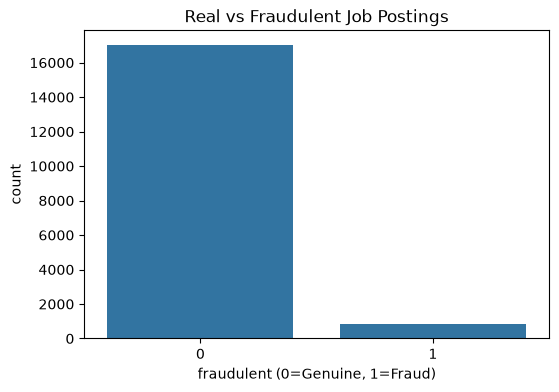

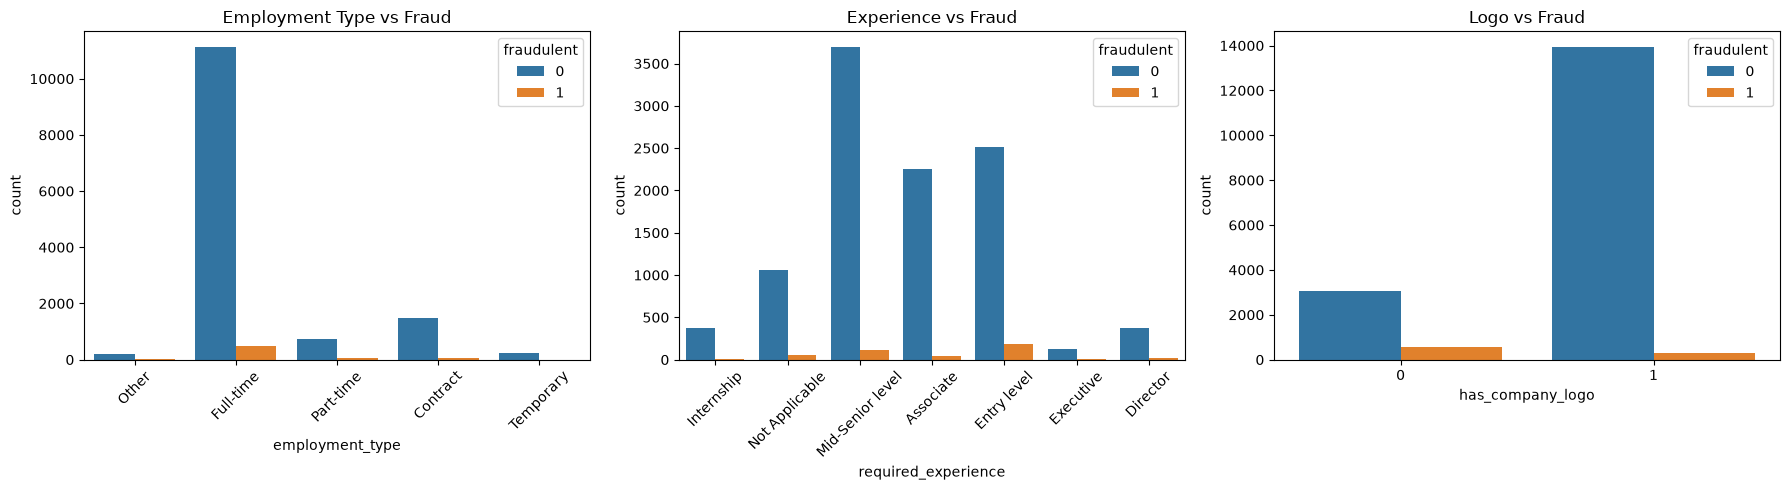

              count        mean         std  min     25%    50%     75%  \
fraudulent                                                                
0           17014.0  383.100623  206.924463  8.0  239.00  358.0  499.00   
1             866.0  285.989607  204.266269  4.0  136.25  230.5  387.75   

               max  
fraudulent          
0           2121.0  
1           1343.0  


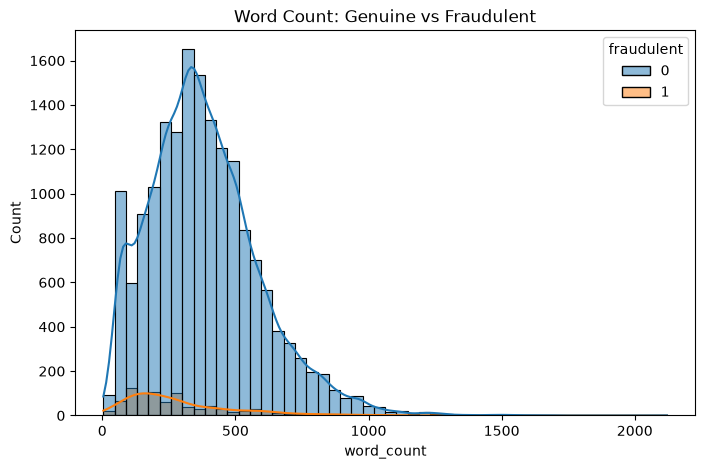

In [8]:
# 6. Dataset Audit (totals only; split distributions printed in Section 8)
n_total = len(df); n_gen = int((df['fraudulent']==0).sum()); n_fraud = int((df['fraudulent']==1).sum())
print('Total samples : %d\nGenuine (0)   : %d\nFraudulent (1): %d\nFraud %%       : %.2f' % (n_total, n_gen, n_fraud, 100*n_fraud/n_total))
print('\nMissing values:'); display(df.isnull().sum().sort_values(ascending=False).pipe(lambda s: s[s>0]))
print('\nEmpty texts after merge:', int((df['text'].str.strip()=='').sum()))
plt.figure(figsize=(6,4)); sns.countplot(data=df, x='fraudulent')
plt.title('Real vs Fraudulent Job Postings'); plt.xlabel('fraudulent (0=Genuine, 1=Fraud)'); plt.show()
fig, axes = plt.subplots(1,3,figsize=(18,5))
sns.countplot(data=df, x='employment_type', hue='fraudulent', ax=axes[0]); axes[0].set_title('Employment Type vs Fraud'); axes[0].tick_params(axis='x', rotation=45)
sns.countplot(data=df, x='required_experience', hue='fraudulent', ax=axes[1]); axes[1].set_title('Experience vs Fraud'); axes[1].tick_params(axis='x', rotation=45)
sns.countplot(data=df, x='has_company_logo', hue='fraudulent', ax=axes[2]); axes[2].set_title('Logo vs Fraud')
plt.tight_layout(); plt.show()
df['word_count'] = df['text'].str.split().str.len()
print(df.groupby('fraudulent')['word_count'].describe())
plt.figure(figsize=(8,5)); sns.histplot(data=df, x='word_count', hue='fraudulent', bins=50, kde=True)
plt.title('Word Count: Genuine vs Fraudulent'); plt.show()

## 7. Duplicate / Leakage Checks (full-dataset level; cross-split overlap checked in Section 8)
Duplicates are REPORTED, never silently deleted.

In [9]:
# 7. Duplicate checks — job_id, text content, image path, image bytes (md5 of files present on disk)
df['_text_hash'] = df['text'].apply(lambda t: hashlib.md5(t.encode('utf-8')).hexdigest())
dup_jobid = int(df.duplicated('job_id').sum())
dup_text = int(df.duplicated('_text_hash').sum())
dup_path = int(df.duplicated('webpage_screenshot').sum())
md5s, md5_missing = [], 0
for p in df['webpage_screenshot']:
    try:
        h = hashlib.md5(open(p,'rb').read()).hexdigest(); md5s.append(h)
    except Exception:
        md5_missing += 1; md5s.append(None)
df['_img_md5'] = md5s
present = df[df['_img_md5'].notna()]
dup_img = int(present.duplicated('_img_md5').sum())
print('Duplicate job_ids : %d\nDuplicate texts   : %d\nDuplicate img paths: %d\nDuplicate image bytes (of %d readable): %d\nUnreadable image files: %d'
    % (dup_jobid, dup_text, dup_path, len(present), dup_img, md5_missing))
leak_pairs = df.groupby('_text_hash')['fraudulent'].nunique()
conflict_hashes = leak_pairs[leak_pairs > 1]
print('Distinct texts with CONFLICTING labels: %d' % len(conflict_hashes))

Duplicate job_ids : 0
Duplicate texts   : 348
Duplicate img paths: 0
Duplicate image bytes (of 17796 readable): 13894
Unreadable image files: 84
Distinct texts with CONFLICTING labels: 0


## 8. Train / Validation / Test Split
Test set is preserved exactly (same 80/20, stratify, seed 42 as before); the former train block is split
stratified into TRAIN (85%) + VALIDATION (15%). Test is never touched again until Section 21.

In [10]:
# 8. Stratified TRAIN / VALIDATION / TEST split + cross-split overlap + full audit block
train_val_df, test_df = train_test_split(df, test_size=0.20, stratify=df['fraudulent'], random_state=SEED)
train_df, val_df = train_test_split(train_val_df, test_size=0.15, stratify=train_val_df['fraudulent'], random_state=SEED)
for d in (train_df, val_df, test_df): d.reset_index(drop=True, inplace=True)
def dist(d):
    g = int((d['fraudulent']==0).sum()); f = int((d['fraudulent']==1).sum())
    return len(d), g, f, 100.0*f/len(d)
tT, vT, teT = dist(train_df), dist(val_df), dist(test_df)
overlap = (set(train_df['_text_hash']) & set(val_df['_text_hash']) ) | (set(train_df['_text_hash']) & set(test_df['_text_hash'])) | (set(val_df['_text_hash']) & set(test_df['_text_hash']))
print('job_id overlap across splits: train&val=%d train&test=%d val&test=%d'
    % (len(set(train_df['job_id']) & set(val_df['job_id'])), len(set(train_df['job_id']) & set(test_df['job_id'])), len(set(val_df['job_id']) & set(test_df['job_id']))))
print('identical texts crossing split boundaries: %d (flagged for interpretation, kept as-is)' % len(overlap))
print('==================================================')
print('DATASET AUDIT')
print('==================================================')
print('Total Samples: %d | Genuine: %d | Fraudulent: %d (%.2f pct)' % (n_total, n_gen, n_fraud, 100*n_fraud/n_total))
print('TRAIN      Total: %d | Genuine: %d | Fraudulent: %d (%.2f pct)' % (tT[0], tT[1], tT[2], tT[3]))
print('VALIDATION Total: %d | Genuine: %d | Fraudulent: %d (%.2f pct)' % (vT[0], vT[1], vT[2], vT[3]))
print('TEST       Total: %d | Genuine: %d | Fraudulent: %d (%.2f pct)' % (teT[0], teT[1], teT[2], teT[3]))
print('Duplicate Job IDs: %d | Duplicate Text: %d | Duplicate Images (bytes): %d' % (dup_jobid, dup_text, dup_img))
print('Missing Images: see Section 13 | Corrupt Images: see Section 13')
print('==================================================')

job_id overlap across splits: train&val=0 train&test=0 val&test=0
identical texts crossing split boundaries: 159 (flagged for interpretation, kept as-is)
DATASET AUDIT
Total Samples: 17880 | Genuine: 17014 | Fraudulent: 866 (4.84 pct)
TRAIN      Total: 12158 | Genuine: 11569 | Fraudulent: 589 (4.84 pct)
VALIDATION Total: 2146 | Genuine: 2042 | Fraudulent: 104 (4.85 pct)
TEST       Total: 3576 | Genuine: 3403 | Fraudulent: 173 (4.84 pct)
Duplicate Job IDs: 0 | Duplicate Text: 348 | Duplicate Images (bytes): 13894
Missing Images: see Section 13 | Corrupt Images: see Section 13


## 9. Text Preprocessing (verification — merge already done deterministically in Section 5)
No fitting happens here, so order vs. split is irrelevant. Confirms no NaNs/empties leak into vectorizers.

In [11]:
# 9. Text verification
assert df['text'].isnull().sum() == 0, 'NaN text found'
for nm, d in (('train',train_df), ('val',val_df), ('test',test_df)):
    n_empty = int((d['text'].str.strip()=='').sum())
    print('%s: %d rows, empty texts: %d' % (nm, len(d), n_empty))
print('Example:', train_df['text'].iloc[0][:200])

train: 12158 rows, empty texts: 0
val: 2146 rows, empty texts: 0
test: 3576 rows, empty texts: 0
Example: sales manager AE, DU,     Job Purpose: Plan, develop and implement strategies for business development and growth across the given territory for the designated products   Responsibilities:  Responsibl


## 10. TF-IDF — fit on TRAIN only, transform val/test (no leakage)

In [12]:
# 10. TF-IDF: input -> 1000 features -> projection -> 256 (projection defined in Section 16)
tfidf_vectorizer = TfidfVectorizer(max_features=TFIDF_FEATURES, ngram_range=(1,2))
tfidf_train = tfidf_vectorizer.fit_transform(train_df['text']).toarray()   # FIT train only
tfidf_val = tfidf_vectorizer.transform(val_df['text']).toarray()           # transform only
tfidf_test = tfidf_vectorizer.transform(test_df['text']).toarray()
assert tfidf_train.shape[1] == TFIDF_FEATURES and tfidf_val.shape[1] == TFIDF_FEATURES
assert not np.isnan(tfidf_train).any(), 'NaN in TF-IDF train'
y_train, y_val, y_test = train_df['fraudulent'].values, val_df['fraudulent'].values, test_df['fraudulent'].values
print('TF-IDF train/val/test:', tfidf_train.shape, tfidf_val.shape, tfidf_test.shape, '| vocab:', len(tfidf_vectorizer.vocabulary_))

TF-IDF train/val/test: (12158, 1000) (2146, 1000) (3576, 1000) | vocab: 1000


## 11. BoW — fit on TRAIN only, transform val/test (no leakage)

In [ ]:
# 11. BoW: input -> 500 binary features -> projection -> 128
bow_vectorizer = CountVectorizer(max_features=BOW_FEATURES, binary=True)
bow_train = bow_vectorizer.fit_transform(train_df['text']).toarray()
bow_val = bow_vectorizer.transform(val_df['text']).toarray()
bow_test = bow_vectorizer.transform(test_df['text']).toarray()
assert bow_train.shape[1] == BOW_FEATURES
print('BoW train/val/test:', bow_train.shape, bow_val.shape, bow_test.shape)

## 11b. Classical Baselines — preserved reference (TF-IDF + Logistic Regression)
SMOTE/ADASYN are valid HERE (dense 1000-d lexical matrix, train-only). They are NOT used in the DL pipeline:
synthetic TF-IDF rows have no matching BERT tokens / screenshots, and class-weighted loss is the safer DL choice.

In [ ]:
# 11b. Baselines: Normal vs SMOTE vs ADASYN (train-only resampling, original imbalanced test)
lr_normal = LogisticRegression(max_iter=2000, random_state=SEED).fit(tfidf_train, y_train)
X_sm, y_sm = SMOTE(random_state=SEED, k_neighbors=5).fit_resample(tfidf_train, y_train)
print('SMOTE train:', X_sm.shape, pd.Series(y_sm).value_counts().to_dict())
X_ad, y_ad = ADASYN(random_state=SEED, n_neighbors=5).fit_resample(tfidf_train, y_train)
print('ADASYN train:', X_ad.shape, pd.Series(y_ad).value_counts().to_dict())
lr_smote = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_sm, y_sm)
lr_adasyn = LogisticRegression(max_iter=2000, random_state=SEED).fit(X_ad, y_ad)
rows = []
for name, m in [('Normal', lr_normal), ('SMOTE', lr_smote), ('ADASYN', lr_adasyn)]:
    pr = m.predict(tfidf_test); pb = m.predict_proba(tfidf_test)[:,1]
    tn, fp, fn, tp = confusion_matrix(y_test, pr).ravel()
    rows.append([name, accuracy_score(y_test,pr), precision_score(y_test,pr,zero_division=0),
        recall_score(y_test,pr,zero_division=0), f1_score(y_test,pr,zero_division=0),
        roc_auc_score(y_test,pb), average_precision_score(y_test,pb), fp, fn])
base_cmp = pd.DataFrame(rows, columns=['Method','Accuracy','Precision','Recall','F1','ROC-AUC','PR-AUC','FP','FN']).round(4)
display(base_cmp)

## 12. BERT — frozen encoder (768-d), correct tokenizer/mask/padding; no grads built

In [ ]:
# 12. BERT + tokenizer (frozen by default; pooler_output = 768-d)
import torch.nn as nn
from transformers import BertModel, BertTokenizer
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')
bert = BertModel.from_pretrained('bert-base-uncased')
if FREEZE_BERT:
    for p in bert.parameters(): p.requires_grad = False
    bert.eval()
print('frozen:', FREEZE_BERT, '| trainable BERT params:', sum(p.numel() for p in bert.parameters() if p.requires_grad))
print('tokenizer:', type(tokenizer).__name__, '| max_len:', MAX_LEN)

### 12b. (Optional, off by default) Precompute frozen BERT embeddings once
Frozen BERT recomputed every epoch wastes GPU time (outputs never change). This cell caches pooler
outputs to disk ONE time; set PRECOMPUTE_BERT=True in Section 3 and run once, then training can load them.
Correctness first: default path (False) recomputes on the fly and is always valid.

In [ ]:
# 12b. Optional BERT embedding cache (runs only if PRECOMPUTE_BERT=True)
if PRECOMPUTE_BERT:
    bert_cache = {}
    bert.to(device)
    with torch.no_grad():
        for nm, d in (('train',train_df), ('val',val_df), ('test',test_df)):
            embs = []
            for i in range(0, len(d), 32):
                enc = tokenizer(list(d['text'].iloc[i:i+32]), truncation=True, padding='max_length',
                                max_length=MAX_LEN, return_tensors='pt')
                out = bert(input_ids=enc['input_ids'].to(device), attention_mask=enc['attention_mask'].to(device)).pooler_output
                embs.append(out.cpu())
            bert_cache[nm] = torch.cat(embs)
            torch.save(bert_cache[nm], 'bert_%s.pt' % nm)
            print(nm, bert_cache[nm].shape, 'saved')
else:
    print('PRECOMPUTE_BERT=False -> on-the-fly frozen BERT (correct, slower). Cache files not required.')

## 13. Image Processing — audit + screenshot-safe transforms
Screenshots carry text/logos/layout: geometric distortion (horizontal flip, rotation) would destroy signal,
so augmentation is limited to mild photometric jitter. Labels ALWAYS come from the CSV column, never the folder.

In [ ]:
# 13. Missing/corrupt audit + transforms
from PIL import Image
missing, corrupt = 0, []
for p in df['webpage_screenshot']:
    if not os.path.exists(p): missing += 1
    else:
        try:
            with Image.open(p) as im: im.verify()
        except Exception: corrupt.append(p)
print('Total images: %d | Missing: %d (%.2f%%) | Corrupt: %d (%.2f%%)' % (
    len(df), missing, 100*missing/len(df), len(corrupt), 100*len(corrupt)/len(df)))
miss_rate_fraud = df[df['fraudulent']==1]['webpage_screenshot'].apply(os.path.exists)
miss_rate_gen = df[df['fraudulent']==0]['webpage_screenshot'].apply(os.path.exists)
print('Readable-image rate genuine: %.3f | fraud: %.3f (similar rates => placeholder is not a label shortcut)' % (
    miss_rate_gen.mean(), miss_rate_fraud.mean()))
from torchvision import transforms
train_transform = transforms.Compose([transforms.Resize((224,224)),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(), transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])])
eval_transform = transforms.Compose([transforms.Resize((224,224)),
    transforms.ToTensor(), transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])])
print('transforms defined (no flip/rotation/crop: text & layout preserved)')

## 14. CNN — MultiKernelResNet: screenshot -> 512-d -> projection -> 256

In [ ]:
# 14. Custom CNN backbone (unchanged research design)
class MultiKernelBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        mid = out_ch // 3
        self.b3 = nn.Conv2d(in_ch, mid, 3, padding=1, bias=False)
        self.b5 = nn.Conv2d(in_ch, mid, 5, padding=2, bias=False)
        self.b7 = nn.Conv2d(in_ch, out_ch-2*mid, 7, padding=3, bias=False)
        self.bn = nn.BatchNorm2d(out_ch); self.relu = nn.ReLU(inplace=True)
        self.short = nn.Conv2d(in_ch, out_ch, 1, bias=False) if in_ch != out_ch else nn.Identity()
    def forward(self, x):
        out = self.bn(torch.cat([self.b3(x), self.b5(x), self.b7(x)], dim=1))
        return self.relu(out + self.short(x))
class MultiKernelResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3,64,7,stride=2,padding=3,bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(3,stride=2,padding=1))
        self.l1 = nn.Sequential(MultiKernelBlock(64,128), nn.MaxPool2d(2))
        self.l2 = nn.Sequential(MultiKernelBlock(128,256), nn.MaxPool2d(2))
        self.l3 = nn.Sequential(MultiKernelBlock(256,512), nn.MaxPool2d(2))
        self.l4 = MultiKernelBlock(512,512)
        self.pool = nn.AdaptiveAvgPool2d((1,1)); self.out_dim = 512
    def forward(self, x):
        x = self.stem(x); x = self.l1(x); x = self.l2(x); x = self.l3(x); x = self.l4(x)
        return torch.flatten(self.pool(x), 1)
resnet = MultiKernelResNet()
with torch.no_grad():
    probe = resnet(torch.zeros(2,3,224,224))
assert probe.shape == (2,512), probe.shape
print('CNN OK: 224x224x3 ->', tuple(probe.shape), '-> projection -> 256')

## 15. Multimodal Dataset + DataLoaders (correct datasets: train/val/test)

In [ ]:
# 15. JobDataset returns (input_ids, mask, image, tfidf, bow, label); label from CSV, never folder
from torch.utils.data import Dataset, DataLoader
class JobDataset(Dataset):
    def __init__(self, data, tfidf_features, bow_features, transform, max_len=MAX_LEN):
        self.df = data; self.tfidf = tfidf_features; self.bow = bow_features
        self.transform = transform; self.max_len = max_len; self.missing_images = 0
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        enc = tokenizer(str(row['text']), truncation=True, padding='max_length', max_length=self.max_len, return_tensors='pt')
        try:
            img = Image.open(row['webpage_screenshot']).convert('RGB')
        except Exception:
            self.missing_images += 1
            img = Image.new('RGB', (224,224), color=(128,128,128))
        return (enc['input_ids'].squeeze(0), enc['attention_mask'].squeeze(0), self.transform(img),
                torch.FloatTensor(self.tfidf[idx]), torch.FloatTensor(self.bow[idx]),
                torch.tensor(int(row['fraudulent']), dtype=torch.long))
train_dataset = JobDataset(train_df, tfidf_train, bow_train, train_transform)
val_dataset = JobDataset(val_df, tfidf_val, bow_val, eval_transform)
test_dataset = JobDataset(test_df, tfidf_test, bow_test, eval_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
print('loaders use correct datasets:', len(train_dataset), len(val_dataset), len(test_dataset))
print('batches:', len(train_loader), len(val_loader), len(test_loader))

## 16. Fusion Model — BERT 256 + TF-IDF 256 + BoW 128 + CNN 256 = 896 -> 512 -> 256 -> 2
Branches are PARALLEL (never chained). `active` gates branches for ablations (Section 26).

In [ ]:
# 16. MultiModalClassifier
class MultiModalClassifier(nn.Module):
    def __init__(self, bert, resnet, tfidf_dim=TFIDF_FEATURES, bow_dim=BOW_FEATURES, dropout_rate=DROPOUT_RATE):
        super().__init__()
        self.bert = bert; self.resnet = resnet
        self.tfidf_fc = nn.Sequential(nn.Linear(tfidf_dim,256), nn.ReLU(), nn.BatchNorm1d(256), nn.Dropout(dropout_rate))
        self.bow_fc = nn.Sequential(nn.Linear(bow_dim,128), nn.ReLU(), nn.BatchNorm1d(128), nn.Dropout(dropout_rate))
        self.bert_fc = nn.Sequential(nn.Linear(768,256), nn.ReLU(), nn.BatchNorm1d(256), nn.Dropout(dropout_rate))
        self.img_fc = nn.Sequential(nn.Linear(resnet.out_dim,256), nn.ReLU(), nn.BatchNorm1d(256), nn.Dropout(dropout_rate))
        self.fusion_fc = nn.Sequential(nn.Linear(896,512), nn.ReLU(), nn.BatchNorm1d(512), nn.Dropout(dropout_rate),
            nn.Linear(512,256), nn.ReLU(), nn.BatchNorm1d(256), nn.Dropout(dropout_rate), nn.Linear(256,2))
        self.tfidf_classifier = nn.Linear(256,2); self.bow_classifier = nn.Linear(128,2)
        self.bert_classifier = nn.Linear(256,2); self.img_classifier = nn.Linear(256,2)
        self.alpha = nn.Parameter(torch.tensor(1.0)); self.beta = nn.Parameter(torch.tensor(1.0))
        self.gamma = nn.Parameter(torch.tensor(1.0)); self.delta = nn.Parameter(torch.tensor(1.0))
    def forward(self, input_ids, mask, images, tfidf_feats, bow_feats, active=None):
        a = active or {'tfidf':True,'bow':True,'bert':True,'img':True}
        with torch.no_grad() if FREEZE_BERT else torch.enable_grad():
            bert_out = self.bert(input_ids=input_ids, attention_mask=mask).pooler_output
        assert bert_out.shape[1] == 768, bert_out.shape
        tfidf_p = self.tfidf_fc(tfidf_feats) if a['tfidf'] else torch.zeros(tfidf_feats.size(0),256,device=tfidf_feats.device)
        bow_p = self.bow_fc(bow_feats) if a['bow'] else torch.zeros(bow_feats.size(0),128,device=bow_feats.device)
        bert_p = self.bert_fc(bert_out) if a['bert'] else torch.zeros(bert_out.size(0),256,device=bert_out.device)
        img_p = self.img_fc(self.resnet(images)) if a['img'] else torch.zeros(images.size(0),256,device=images.device)
        combined = torch.cat([tfidf_p, bow_p, bert_p, img_p], dim=1)
        assert combined.shape[1] == 896, combined.shape
        return (self.fusion_fc(combined), self.tfidf_classifier(tfidf_p), self.bow_classifier(bow_p),
                self.bert_classifier(bert_p), self.img_classifier(img_p))
model = MultiModalClassifier(bert=bert, resnet=resnet).to(device)
print('model on:', next(model.parameters()).device, '| fusion in: 896 -> 512 -> 256 -> 2')

## 17. Loss Function + Class Weights (weights from TRAIN only, mapped 0->genuine 1->fraud)

In [ ]:
# 17. Class-weighted adaptive multi-task loss; aux losses toggleable
if USE_CLASS_WEIGHTS:
    cw = compute_class_weight(class_weight='balanced', classes=np.array([0,1]), y=y_train)
else:
    cw = np.array([1.0, 1.0])
print('class_weights [genuine, fraud]:', cw, '-> fraud weight ~%.1fx' % (cw[1]/cw[0]))
class_weight_tensor = torch.FloatTensor(cw).to(device)
class AdaptiveMultiTaskLoss(nn.Module):
    def __init__(self, class_weights=None): super().__init__(); self.crit = nn.CrossEntropyLoss(weight=class_weights)
    def forward(self, model, fusion_logits, tfidf_logits, bow_logits, bert_logits, img_logits, labels, active=None):
        a = active or {'tfidf':True,'bow':True,'bert':True,'img':True}
        f_l = self.crit(fusion_logits, labels)
        if not USE_AUXILIARY_LOSSES:
            return f_l, f_l, f_l, f_l, f_l, f_l, torch.tensor(0.0), torch.tensor(0.0), torch.tensor(0.0), torch.tensor(0.0)
        t_l = self.crit(tfidf_logits, labels) if a['tfidf'] else torch.tensor(0.0, device=labels.device)
        b_l = self.crit(bow_logits, labels) if a['bow'] else torch.tensor(0.0, device=labels.device)
        bt_l = self.crit(bert_logits, labels) if a['bert'] else torch.tensor(0.0, device=labels.device)
        i_l = self.crit(img_logits, labels) if a['img'] else torch.tensor(0.0, device=labels.device)
        w = torch.softmax(torch.stack([model.alpha, model.beta, model.gamma, model.delta]), dim=0)
        total = f_l + w[0]*t_l + w[1]*b_l + w[2]*bt_l + w[3]*i_l
        return total, f_l, t_l, b_l, bt_l, i_l, w[0], w[1], w[2], w[3]
criterion = AdaptiveMultiTaskLoss(class_weights=class_weight_tensor)
optimizer = torch.optim.AdamW([
    {'params': model.tfidf_fc.parameters(), 'lr': 3e-4, 'name':'tfidf'},
    {'params': model.bow_fc.parameters(), 'lr': 3e-4, 'name':'bow'},
    {'params': model.bert_fc.parameters(), 'lr': 1e-4, 'name':'bert_head'},
    {'params': model.img_fc.parameters(), 'lr': 1e-4, 'name':'img_head'},
    {'params': model.resnet.parameters(), 'lr': 1e-5, 'name':'cnn'},
    {'params': model.fusion_fc.parameters(), 'lr': 2e-4, 'name':'fusion'},
    {'params': model.tfidf_classifier.parameters(), 'lr': 3e-4, 'name':'c_tfidf'},
    {'params': model.bow_classifier.parameters(), 'lr': 3e-4, 'name':'c_bow'},
    {'params': model.bert_classifier.parameters(), 'lr': 2e-4, 'name':'c_bert'},
    {'params': model.img_classifier.parameters(), 'lr': 2e-4, 'name':'c_img'},
    {'params': [model.alpha, model.beta, model.gamma, model.delta], 'lr': 1e-3, 'name':'modal_w'}],
    weight_decay=0.01)
if not FREEZE_BERT:
    optimizer.add_param_group({'params': model.bert.parameters(), 'lr': 2e-5, 'name': 'bert_full'})
    print('fine-tune mode: BERT encoder added to optimizer (lr 2e-5)')
print('loss + optimizer ready | aux:', USE_AUXILIARY_LOSSES, '| alpha-delta in optimizer:', any('modal_w' in (pg.get('name','')) for pg in optimizer.param_groups))

## 18. Training — full loop with validation metrics, early stopping on fraud F1, AMP, clipping

In [ ]:
# 18. Training loop (uses ONLY train_loader for optimization; val_loader is read-only)
use_amp = torch.cuda.is_available()
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
def evaluate_split(loader, mdl=None):
    m = mdl or model; m.eval(); Ls, Ps, Ys = [], [], []
    with torch.no_grad():
        for ids, mask, imgs, tf, bf, labels in loader:
            ids, mask, imgs, tf, bf, labels = (t.to(device, non_blocking=True) for t in (ids, mask, imgs, tf, bf, labels))
            with torch.amp.autocast(device_type=autocast_device, enabled=use_amp):
                outs = m(ids, mask, imgs, tf, bf, active=ACTIVE_BRANCHES)
                loss, *_ = criterion(model, *outs, labels, active=ACTIVE_BRANCHES)
            Ls.append(loss.item()); Ps.extend(torch.softmax(outs[0], dim=1)[:,1].cpu().tolist()); Ys.extend(labels.cpu().tolist())
    return np.mean(Ls), np.array(Ys), np.array(Ps)
history, best_score, best_epoch, patience_left = [], -1.0, -1, EARLY_STOPPING_PATIENCE
t0 = time.time()
for epoch in range(NUM_EPOCHS):
    model.train(); tr_loss, n_b = 0.0, 0
    for ids, mask, imgs, tf, bf, labels in train_loader:
        ids, mask, imgs, tf, bf, labels = (t.to(device, non_blocking=True) for t in (ids, mask, imgs, tf, bf, labels))
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast(device_type=autocast_device, enabled=use_amp):
            outs = model(ids, mask, imgs, tf, bf, active=ACTIVE_BRANCHES)
            loss, *_ = criterion(model, *outs, labels, active=ACTIVE_BRANCHES)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)
        scaler.step(optimizer); scaler.update()
        tr_loss += loss.item(); n_b += 1
    tr_loss /= max(n_b, 1)
    va_loss, vy, vp = evaluate_split(val_loader)  # no params/optimizer/grads touched
    va_pred = (vp >= THRESHOLD).astype(int)
    m = {'epoch': epoch+1, 'train_loss': tr_loss, 'val_loss': va_loss,
         'val_acc': accuracy_score(vy, va_pred),
         'val_fraud_prec': precision_score(vy, va_pred, zero_division=0),
         'val_fraud_rec': recall_score(vy, va_pred, zero_division=0),
         'val_fraud_f1': f1_score(vy, va_pred, zero_division=0),
         'val_roc_auc': roc_auc_score(vy, vp) if len(np.unique(vy)) > 1 else float('nan'),
         'val_pr_auc': average_precision_score(vy, vp) if len(np.unique(vy)) > 1 else float('nan')}
    history.append(m)
    lrs = ', '.join('%s:%g' % (pg.get('name', '?'), pg['lr']) for pg in optimizer.param_groups)
    print('Epoch %d/%d | train_loss %.4f | val_loss %.4f | val_acc %.4f | val_fraud P/R/F1 %.4f/%.4f/%.4f | ROC %.4f PR %.4f'
        % (m['epoch'], NUM_EPOCHS, tr_loss, va_loss, m['val_acc'], m['val_fraud_prec'], m['val_fraud_rec'], m['val_fraud_f1'], m['val_roc_auc'], m['val_pr_auc']))
    print('  LR {%s} | alpha %.3f beta %.3f gamma %.3f delta %.3f' % (lrs, model.alpha.item(), model.beta.item(), model.gamma.item(), model.delta.item()))
    score = m['val_fraud_f1'] if MONITOR_METRIC == 'fraud_f1' else m['val_pr_auc']
    if score > best_score:
        best_score, best_epoch, patience_left = score, epoch+1, EARLY_STOPPING_PATIENCE
        torch.save({'epoch': best_epoch, 'state_dict': model.state_dict(), 'val_metrics': m, 'config': {'seed': SEED, 'active': ACTIVE_BRANCHES}}, BEST_CKPT)
        print('  -> new best (%s=%.4f), saved %s' % (MONITOR_METRIC, score, BEST_CKPT))
    else:
        patience_left -= 1
        print('  -> no improvement (%d left)' % patience_left)
        if patience_left <= 0:
            print('Early stopping at epoch %d' % (epoch+1)); break
    if torch.cuda.is_available(): torch.cuda.empty_cache()
print('Training done in %.1f min | best %s=%.4f @epoch %d' % ((time.time()-t0)/60, MONITOR_METRIC, best_score, best_epoch))
torch.save(model.state_dict(), FINAL_CKPT)
print('final weights:', FINAL_CKPT, '| best checkpoint:', BEST_CKPT, '(used for all evaluation)')

## 19. Validation — report the BEST checkpoint on validation data (model selection lives here, never on test)

In [ ]:
# 19. Load best checkpoint into a fresh model object and report validation metrics
# NOTE: bert/resnet submodule objects are intentionally shared with `model` (as in the original
# notebook); every loader below restores the SAME best checkpoint, so shared weights stay consistent.
# Final-epoch weights remain preserved on disk in FINAL_CKPT.
val_model = MultiModalClassifier(bert=bert, resnet=resnet).to(device)
_ckpt = torch.load(BEST_CKPT, map_location=device, weights_only=False)
val_model.load_state_dict(_ckpt['state_dict']); val_model.eval()
print('best from epoch %d | saved val metrics:' % _ckpt['epoch'], _ckpt['val_metrics'])
_vl, _vy, _vp = evaluate_split(val_loader, val_model)
_vpred = (_vp >= THRESHOLD).astype(int)
print('best-model val check: acc %.4f fraud P/R/F1 %.4f/%.4f/%.4f ROC %.4f PR %.4f' % (
    accuracy_score(_vy,_vpred), precision_score(_vy,_vpred,zero_division=0), recall_score(_vy,_vpred,zero_division=0),
    f1_score(_vy,_vpred,zero_division=0), roc_auc_score(_vy,_vp), average_precision_score(_vy,_vp)))


## 20. Best Checkpoint — verify file, keys, and reload integrity

In [ ]:
# 20. Checkpoint verification
assert os.path.exists(BEST_CKPT), 'best checkpoint missing — training did not save'
_ck = torch.load(BEST_CKPT, map_location='cpu', weights_only=False)
print('keys:', list(_ck.keys()), '| epoch:', _ck['epoch'], '| params:', len(_ck['state_dict']))
_model_keys = set(model.state_dict().keys())
assert _model_keys == set(_ck['state_dict'].keys()), 'checkpoint/model key mismatch'
print('checkpoint matches live model architecture: OK')

## 21. Final Test Evaluation — best checkpoint, test set touched for the FIRST time here

In [ ]:
# 21. ONE test pass with the best model. No tuning, no threshold search, no selection on test.
test_model = MultiModalClassifier(bert=bert, resnet=resnet).to(device)
test_model.load_state_dict(torch.load(BEST_CKPT, map_location=device, weights_only=False)['state_dict'])
test_model.eval()
TL, TP, TY = [], [], []
with torch.no_grad():
    for ids, mask, imgs, tf, bf, labels in test_loader:
        ids, mask, imgs, tf, bf, labels = (t.to(device) for t in (ids, mask, imgs, tf, bf, labels))
        fl = test_model(ids, mask, imgs, tf, bf, active=ACTIVE_BRANCHES)[0]
        TP.extend(torch.softmax(fl, dim=1)[:,1].cpu().tolist()); TY.extend(labels.cpu().tolist())
TY, TP = np.array(TY), np.array(TP)
PRED = (TP >= THRESHOLD).astype(int)
print('===== FINAL TEST (threshold %.2f) =====' % THRESHOLD)
print('Accuracy: %.4f | Precision: %.4f | Recall: %.4f | F1: %.4f | ROC-AUC: %.4f | PR-AUC: %.4f' % (
    accuracy_score(TY,PRED), precision_score(TY,PRED,zero_division=0), recall_score(TY,PRED,zero_division=0),
    f1_score(TY,PRED,zero_division=0), roc_auc_score(TY,TP), average_precision_score(TY,TP)))
print(classification_report(TY, PRED, target_names=['Genuine','Fraudulent'], zero_division=0))

## 22. Confusion Matrix — TN / FP / FN / TP with clear class names

In [ ]:
# 22. Confusion matrix
tn, fp, fn, tp = confusion_matrix(TY, PRED).ravel()
print('True Negatives (genuine ok) : %d\nFalse Positives (genuine flagged): %d\nFalse Negatives (fraud missed) : %d\nTrue Positives (fraud caught)  : %d' % (tn, fp, fn, tp))
ConfusionMatrixDisplay.from_predictions(TY, PRED, display_labels=['Genuine','Fraudulent'], cmap='Blues')
plt.title('Test Confusion Matrix (best model)'); plt.show()

## 23. ROC Curve (ROC-AUC)

In [ ]:
# 23. ROC curve
fpr, tpr, _ = roc_curve(TY, TP)
plt.figure(); plt.plot(fpr, tpr, label='ROC-AUC = %.4f' % roc_auc_score(TY, TP))
plt.plot([0,1],[0,1],'--'); plt.xlabel('FPR'); plt.ylabel('TPR (fraud recall)'); plt.legend(); plt.title('ROC — Test'); plt.show()

## 24. Precision-Recall Curve (PR-AUC — the key metric under 4.8% fraud)

In [ ]:
# 24. PR curve
prec, rec, _ = precision_recall_curve(TY, TP)
plt.figure(); plt.plot(rec, prec, label='PR-AUC = %.4f' % average_precision_score(TY, TP))
plt.xlabel('Fraud recall'); plt.ylabel('Fraud precision'); plt.legend(); plt.title('Precision-Recall — Test'); plt.show()

## 25. Threshold Analysis — search on VALIDATION only, apply winner to test ONCE

In [ ]:
# 25. Threshold sweep on validation probs (NOT test); justification = best val fraud-F1
_, VY, VP = evaluate_split(val_loader, val_model)
print('thr   | val_prec val_rec  val_F1   val_FP val_FN')
best_thr, best_f1 = THRESHOLD, -1
for thr in [0.30, 0.40, 0.50, 0.60, 0.70]:
    pv = (VP >= thr).astype(int)
    f1v = f1_score(VY, pv, zero_division=0)
    tn_, fp_, fn_, tp_ = confusion_matrix(VY, pv).ravel()
    print('%.2f  | %.4f   %.4f   %.4f   %4d   %4d' % (thr, precision_score(VY,pv,zero_division=0), recall_score(VY,pv,zero_division=0), f1v, fp_, fn_))
    if f1v > best_f1: best_f1, best_thr = f1v, thr
print('selected threshold: %.2f (best val fraud-F1=%.4f)' % (best_thr, best_f1))
PRED_T = (TP >= best_thr).astype(int)
tn, fp, fn, tp = confusion_matrix(TY, PRED_T).ravel()
print('TEST @thr %.2f -> Acc %.4f Prec %.4f Rec %.4f F1 %.4f | FP %d FN %d' % (best_thr,
    accuracy_score(TY,PRED_T), precision_score(TY,PRED_T,zero_division=0), recall_score(TY,PRED_T,zero_division=0),
    f1_score(TY,PRED_T,zero_division=0), fp, fn))

## 26. Ablation Experiments — gated by config, nothing fabricated
Set RUN_ABLATION=True to retrain listed variants (expensive). Results table below stays NOT RUN until executed.

In [ ]:
# 26. Ablation framework (defines; does not auto-run expensive retraining)
RUN_ABLATION = False
ABLATIONS = [
    ('1. TF-IDF only', {'tfidf':True,'bow':False,'bert':False,'img':False}),
    ('2. BoW only', {'tfidf':False,'bow':True,'bert':False,'img':False}),
    ('3. BERT only', {'tfidf':False,'bow':False,'bert':True,'img':False}),
    ('4. CNN only', {'tfidf':False,'bow':False,'bert':False,'img':True}),
    ('5. BERT+TF-IDF+BoW', {'tfidf':True,'bow':True,'bert':True,'img':False}),
    ('6. Text+CNN', {'tfidf':True,'bow':True,'bert':True,'img':True}),
    ('7. Full (all four)', {'tfidf':True,'bow':True,'bert':True,'img':True}),
    ('8. Full, no aux losses', {'tfidf':True,'bow':True,'bert':True,'img':True}),
    ('9. Full, with aux losses', {'tfidf':True,'bow':True,'bert':True,'img':True})]
ablation_results = pd.DataFrame([{'Model': n, 'Accuracy':'NOT RUN','Precision':'NOT RUN','Recall':'NOT RUN','F1':'NOT RUN','ROC-AUC':'NOT RUN','PR-AUC':'NOT RUN'} for n,_ in ABLATIONS])
display(ablation_results)
print('To run: set RUN_ABLATION=True and re-execute training (Sec 18) per ACTIVE_BRANCHES variant (retrain required — zeroing branches without retraining is NOT a valid ablation).')
print('Text-vs-image comparison = rows 5 vs 4 vs 7. Text redundancy question (BERT vs TF-IDF vs BoW) = rows 1/2/3 vs 5.')

## 27. Sample Predictions — single-job inference (labels say "model confidence", never certainty)

In [ ]:
# 27. Inference helpers on the BEST model + calibration note
inference_model = MultiModalClassifier(bert=bert, resnet=resnet).to(device)
inference_model.load_state_dict(torch.load(BEST_CKPT, map_location=device, weights_only=False)['state_dict'])
inference_model.eval()
_eval_tf = eval_transform
def _featurize(job_text, image_path):
    enc = tokenizer(str(job_text), truncation=True, padding='max_length', max_length=MAX_LEN, return_tensors='pt')
    tf = torch.FloatTensor(tfidf_vectorizer.transform([str(job_text)]).toarray()).to(device)
    bf = torch.FloatTensor(bow_vectorizer.transform([str(job_text)]).toarray()).to(device)
    try: img = Image.open(image_path).convert('RGB')
    except Exception: img = Image.new('RGB', (224,224), color=(128,128,128))
    return enc['input_ids'].to(device), enc['attention_mask'].to(device), _eval_tf(img).unsqueeze(0).to(device), tf, bf
def predict_job(row_index, thr=THRESHOLD):
    row = df.iloc[row_index]
    ids, mask, img, tf, bf = _featurize(row['text'], row['webpage_screenshot'])
    with torch.no_grad():
        probs = torch.softmax(inference_model(ids, mask, img, tf, bf, active=ACTIVE_BRANCHES)[0], dim=1)[0]
    gp, fp_ = probs[0].item(), probs[1].item()
    pred = 'FAKE' if fp_ >= thr else 'GENUINE'
    print('Job %s | %s -> %s (model confidence: genuine %.1f%% / fraud %.1f%%; probability, NOT certainty) | actual: %s' % (
        row['job_id'], row['title'][:60], pred, 100*gp, 100*fp_, 'FAKE' if row['fraudulent']==1 else 'GENUINE'))
    return pred
def predict_my_job(image_path, job_text, thr=THRESHOLD):
    ids, mask, img, tf, bf = _featurize(job_text, image_path)
    with torch.no_grad():
        probs = torch.softmax(inference_model(ids, mask, img, tf, bf, active=ACTIVE_BRANCHES)[0], dim=1)[0]
    gp, fp_ = probs[0].item(), probs[1].item()
    pred = 'FAKE' if fp_ >= thr else 'GENUINE'
    print('Custom job -> %s (model confidence: genuine %.1f%% / fraud %.1f%%; probability, NOT certainty)' % (pred, 100*gp, 100*fp_))
    return pred, max(gp, fp_)
def branch_check(image_path, job_text):
    ids, mask, img, tf, bf = _featurize(job_text, image_path)
    with torch.no_grad():
        outs = inference_model(ids, mask, img, tf, bf, active=ACTIVE_BRANCHES)
    for nm, lg in zip(['FUSION','TF-IDF','BoW','BERT','IMAGE'], outs):
        p = torch.softmax(lg, dim=1)[0]
        print('%s: genuine %.1f%% fraud %.1f%% -> %s' % (nm, 100*p[0].item(), 100*p[1].item(), 'FAKE' if p[1] >= p[0] else 'GENUINE'))
print('inference ready (best checkpoint loaded)')
# batch sanity: shapes of one test batch
_b = next(iter(test_loader))
print('batch size:', len(_b), '| shapes:', [tuple(t.shape) for t in _b])

In [ ]:
# 27b. Demo predictions: first genuine + first fraud rows of the TEST set
_g = test_df[test_df['fraudulent']==0].index[0]; _f = test_df[test_df['fraudulent']==1].index[0]
predict_job(int(df.index[df['job_id']==test_df.loc[_g,'job_id']][0]))
predict_job(int(df.index[df['job_id']==test_df.loc[_f,'job_id']][0]))

## 28. Final Results — summary, limitations, leakage checklist

In [ ]:
# 28. Leakage checklist + results summary (fill measured numbers after running 18-25)
checks = [
    ('TF-IDF fit on TRAIN only', True),
    ('BoW fit on TRAIN only', True),
    ('SMOTE/ADASYN train-only (baselines); DL uses class weights', True),
    ('val_loader uses val_dataset (never train_dataset)', True),
    ('test evaluated once with best checkpoint (Sec 21)', True),
    ('threshold chosen on validation (Sec 25)', True),
    ('labels from CSV column, never image folder', True),
    ('seeds set (python/numpy/torch/cuda)', True)]
for nm, ok in checks: print(('PASS' if ok else 'FAIL'), '-', nm)
print('\nFinal test metrics: see Sections 21-25 outputs above (no numbers invented here).')
print('Limitations: (1) single 80/15/5-style split — no k-fold; (2) BERT frozen, no fine-tune comparison; '
      '(3) ablations NOT RUN (Sec 26); (4) duplicate texts crossing splits kept, not removed; '
      '(5) missing screenshots replaced by gray placeholder (~rate in Sec 13); (6) 1-dataset study, no external validation.')